# Grammar Scoring Engine for Spoken Audio: Report

## 1. Problem
Predict a continuous grammar score (0 to 5) for 45 to 60 s spoken clips. Train: 769 labelled clips; test: 216. Metric: RMSE.

## 2. Data observations
- Audio is 16 kHz mono; durations 6 to 61 s. Labels centre on 3 (mean 3.31, std 1.24). The mean-prediction baseline RMSE is **1.238**.
- **37 clips have score 0**, although the rubric starts at 1. They show continuous flat loudness with no pauses and incoherent ASR output, and all have filenames `audio_5037` to `audio_5073` (a contiguous block, probably from a different source).
- **Filenames are not unique:** 212 of 216 test filenames also exist in `train/`, but the audio differs (0 byte-identical files). All merges use a `split/filename` key, so there is no leakage.
- `sample_submission.csv` (204 rows) does not match `test.csv` (216 rows). Predictions are produced for all 216 rows of `test.csv`.

## 3. Preprocessing and features
- Audio: loaded at 16 kHz mono, peak-normalised; pause, speech-ratio and loudness statistics computed.
- Transcription: Whisper `small` (English, a filler-word prompt to keep disfluencies). Transcripts cached.
- Text features: spaCy syntax and disfluency features; CoLA acceptability per sentence (RoBERTa); GPT-2 token loss; RoBERTa mean-pooled embeddings.
- Audio features: Whisper-**medium encoder** embeddings (last and middle layer, mean and std pooled over 30 s chunks), taken directly from the audio, so they keep fluency and pronunciation cues that the transcript loses.
- Final feature matrix: about 4,911 columns.

## 4. Pipeline architecture
1. **Zero detector:** logistic regression (balanced class weights) on 10 acoustic, ASR-confidence and text features, giving p(zero).
2. **Regressor:** Ridge (standardised features, alpha by internal CV), trained on non-zero clips only.
3. **Combination:** prediction = (1 - p(zero)) x Ridge output, clipped to [0, 5].
4. **Calibration:** isotonic regression fitted on out-of-fold predictions.

## 5. Evaluation (5-fold stratified CV, same folds for all models)
**Training RMSE (final pipeline): 0.2651** (required figure).
**Cross-validated RMSE: 0.5238** (nested calibration), against a baseline of 1.2383. Pearson 0.906, Spearman 0.863.
Repeated CV with three other fold seeds gave uncalibrated RMSE 0.530 to 0.548, so differences below about 0.02 between variants are within noise.
The training RMSE is much lower than the CV RMSE because the feature count (about 4,900) far exceeds the sample count (about 730); the CV figure is the estimate of test performance.

| Feature set (Ridge, non-zero clips) | RMSE |
|---|---|
| Hand-crafted only | 0.716 |
| + RoBERTa embeddings | 0.616 |
| + Whisper-medium encoder (last + middle) | 0.507 |

Earlier experiments: LightGBM was dropped because it added nothing once encoder features were included; a smaller (Whisper-small) encoder gave 0.525.

## 6. Interpretation
Audio-derived encoder features gave the largest gain, which suggests that transcripts alone lose information relevant to grammar scoring, such as hesitation and fluency (this was not tested directly).Among interpretable features, CoLA sentence acceptability (mean, fraction acceptable, minimum) correlates most strongly with the score (r about 0.43 to 0.55 on non-zero clips), followed by GPT-2 fluency loss (negative), word count, and ASR confidence (r about 0.3). Predictions follow the diagonal, with the usual pull toward the middle at the extremes; residuals are roughly symmetric.

## 7. Limitations
- Whisper smooths grammar errors, which limits accuracy on low scores.
- Predictions are compressed toward the mean (test range 2.15 to 4.95).
- Feature sets were compared on the same folds, so the CV figure is slightly optimistic.
- Rare labels (1.0 and 1.5 have 1 and 3 samples) cannot be learned.
- The isotonic calibrator has a gap in its low range, and the zero-detector probabilities are inflated by balanced class weights.
- Speaker identity is not provided, so CV cannot guarantee speaker-disjoint folds.

## Part A: Setup
Installs libraries, mounts Drive, unzips the data, and builds a unique `split/filename` key for every clip (filenames collide between `train/` and `test/`).


In [1]:
# Cell 1: Install dependencies
# Whisper (ASR), transformers (CoLA/GPT-2/RoBERTa), librosa (audio), spaCy (syntax), scikit-learn (models).
!pip install -q openai-whisper transformers librosa soundfile spacy lightgbm scikit-learn seaborn
!python -m spacy download en_core_web_sm -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 31.9 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
# Cell 2: Imports, random seed, and GPU check
# A fixed seed keeps the CV folds and results reproducible.
import os, re, json, gc, time, hashlib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import librosa, soundfile as sf, torch
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "")

Device: cuda Tesla T4


In [3]:
# Cell 3: Mount Google Drive and unzip the dataset to local disk
# Local disk is much faster than Drive for reading ~1,000 audio files.
from google.colab import drive
drive.mount('/content/drive')
ZIP_PATH = "/content/drive/MyDrive/shl-hiring-assessment-2026.zip"
!mkdir -p /content/data
!unzip -q -o "{ZIP_PATH}" -d /content/data

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# Cell 4: Paths and constants
# WORK_DIR is on Drive: all slow outputs (transcripts, features, embeddings) are cached there.
BASE_DIR = "/content/data/Dataset_Final"
TRAIN_AUDIO_DIR, TEST_AUDIO_DIR = f"{BASE_DIR}/train", f"{BASE_DIR}/test"
WORK_DIR = "/content/drive/MyDrive/grammar_work"      # cache for transcripts and features
os.makedirs(WORK_DIR, exist_ok=True)
SR = 16000

In [5]:
# Cell 5: Load CSVs and build unique keys
# 212 of 216 test filenames also exist in train/ (different audio), so key = split/filename.
train_df = pd.read_csv(f"{BASE_DIR}/train.csv")
test_df  = pd.read_csv(f"{BASE_DIR}/test.csv")
sub_df   = pd.read_csv(f"{BASE_DIR}/sample_submission.csv")

# filenames collide between train/ and test/, so use split/filename as the key
train_df["key"] = "train/" + train_df["filename"]
test_df["key"]  = "test/"  + test_df["filename"]
train_df["path"] = TRAIN_AUDIO_DIR + "/" + train_df["filename"]
test_df["path"]  = TEST_AUDIO_DIR  + "/" + test_df["filename"]

print("Train:", train_df.shape, "| Test:", test_df.shape, "| Sample sub:", sub_df.shape)
print("Missing files:", (~train_df["path"].apply(os.path.exists)).sum(),
      (~test_df["path"].apply(os.path.exists)).sum())
print("Unique keys:", pd.concat([train_df["key"], test_df["key"]]).nunique(), "of 985")
y = train_df["label"].values

Train: (769, 4) | Test: (216, 4) | Sample sub: (204, 2)
Missing files: 0 0
Unique keys: 985 of 985


## Part B: Data checks (EDA)
Inspects the label distribution, durations, filename collisions, the `sample_submission.csv` mismatch, and the score-0 clips.

label
0.0     37
1.0      1
1.5      3
2.0    102
2.5     79
3.0    174
3.5     64
4.0    124
4.5     52
5.0    133
Name: count, dtype: int64
Baseline RMSE (predict the mean): 1.2382


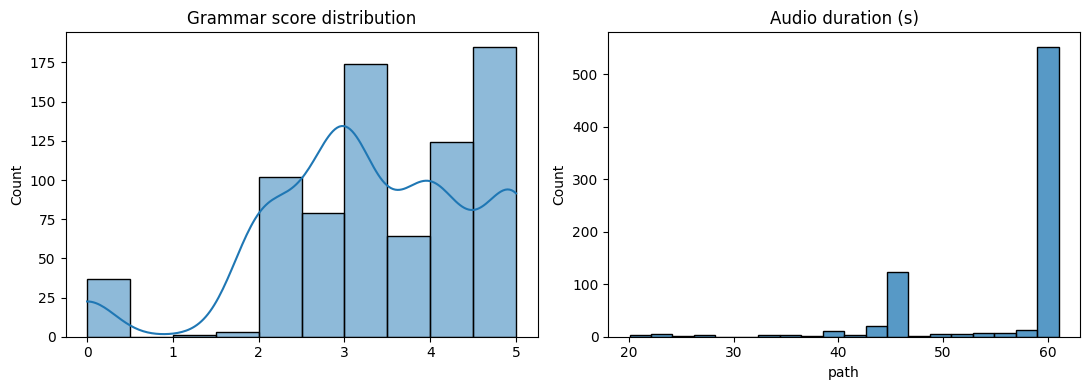

In [6]:
# Cell 6: Label distribution, mean-prediction baseline, and audio durations
# The baseline RMSE (always predict the training mean) is the number to beat.
print(train_df["label"].value_counts().sort_index())
print(f"Baseline RMSE (predict the mean): {np.sqrt(((y - y.mean())**2).mean()):.4f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(y, bins=10, kde=True, ax=ax[0]); ax[0].set_title("Grammar score distribution")
dur = train_df["path"].apply(lambda p: sf.info(p).duration)
sns.histplot(dur, bins=20, ax=ax[1]); ax[1].set_title("Audio duration (s)")
plt.tight_layout(); plt.show()

In [7]:
# Cell 7: Data-quality checks
# Confirms train/test same-named files are different audio (no leakage), shows the
# sample_submission mismatch, and shows that all score-0 clips are in one id block (5037-5073).
def md5(p):
    with open(p, "rb") as f: return hashlib.md5(f.read()).hexdigest()

common = sorted(set(train_df["filename"]) & set(test_df["filename"]))
same = sum(md5(f"{TRAIN_AUDIO_DIR}/{f}") == md5(f"{TEST_AUDIO_DIR}/{f}") for f in common)
print(f"Same-named train/test pairs: {len(common)} | byte-identical: {same}")
print("sample_submission names found in test.csv:", len(set(sub_df['filename']) & set(test_df['filename'])), "of", len(sub_df))
ids = train_df["filename"].str.extract(r"(\d+)")[0].astype(int)
print("Score-0 file ids:", ids[y == 0].min(), "to", ids[y == 0].max(),
      "| non-zero max id:", ids[y > 0].max())

Same-named train/test pairs: 212 | byte-identical: 0
sample_submission names found in test.csv: 25 of 204
Score-0 file ids: 5037 to 5073 | non-zero max id: 784


## Part C: Audio features and transcription
Extracts pause/loudness statistics from the audio, then transcribes every clip with Whisper `small`. Outputs are cached to Drive so a disconnect never costs progress.

In [8]:
# Cell 8: Audio preprocessing and acoustic features
# Peak-normalise 16 kHz mono audio; compute speech ratio, pause statistics, and loudness (RMS) features.
def load_audio(path):
    y_, _ = librosa.load(path, sr=SR, mono=True)
    return (y_ / (np.max(np.abs(y_)) + 1e-9)).astype(np.float32)

def acoustic_features(y_, top_db=30, min_pause=0.3):
    dur = len(y_) / SR
    iv = librosa.effects.split(y_, top_db=top_db)
    speech = sum(e - s for s, e in iv) / SR
    gaps = [(iv[i+1][0] - iv[i][1]) / SR for i in range(len(iv) - 1)]
    lp = [g for g in gaps if g >= min_pause]
    rms = librosa.feature.rms(y=y_)[0]
    return {"dur": dur, "speech_ratio": speech / dur, "n_segments": len(iv),
            "n_pauses": len(lp), "pause_total": float(np.sum(lp)) if lp else 0.0,
            "pause_mean": float(np.mean(lp)) if lp else 0.0, "pause_max": float(np.max(lp)) if lp else 0.0,
            "rms_mean": float(rms.mean()), "rms_std": float(rms.std())}

ACOUSTIC_CSV = f"{WORK_DIR}/acoustic_feats.csv"
all_files = pd.concat([train_df[["key", "path"]], test_df[["key", "path"]]], ignore_index=True)
if os.path.exists(ACOUSTIC_CSV):
    acoustic_df = pd.read_csv(ACOUSTIC_CSV)
else:
    rows = []
    for key, p in tqdm(all_files.itertuples(index=False), total=len(all_files)):
        f = acoustic_features(load_audio(p)); f["key"] = key; rows.append(f)
    acoustic_df = pd.DataFrame(rows); acoustic_df.to_csv(ACOUSTIC_CSV, index=False)
print(acoustic_df.shape)

(985, 10)


In [9]:
# Cell 9: Compare score-0 clips with the rest
# Score-0 clips have no pauses and flat loudness; this motivates a separate zero detector.
tmp = train_df.merge(acoustic_df, on="key")
tmp["is_zero"] = tmp["label"] == 0
print(tmp.groupby("is_zero")[["speech_ratio", "n_segments", "n_pauses", "rms_mean", "rms_std"]].mean().round(4))

         speech_ratio  n_segments  n_pauses  rms_mean  rms_std
is_zero                                                       
False          0.7039     36.8142   13.7309    0.0571   0.0542
True           1.0000      1.0000    0.0000    0.1263   0.0222


In [10]:
# Cell 10: Load Whisper 'small' and define the transcription function
# A filler-word prompt encourages Whisper to keep disfluencies ("umm", repeats).
# Also returns confidence signals: avg_logprob and no_speech_prob.
import whisper
WHISPER_SIZE = "small"
model = whisper.load_model(WHISPER_SIZE, device=device)
PROMPT = "Umm, so, uh, I think, you know, like, I was going to the market and, um, I bought some things."

def transcribe_one(path):
    r = model.transcribe(load_audio(path), language="en", fp16=(device == "cuda"),
                         word_timestamps=False, condition_on_previous_text=False,
                         initial_prompt=PROMPT)
    segs = r["segments"]
    return {"text": r["text"].strip(),
            "avg_logprob": float(np.mean([s["avg_logprob"] for s in segs])) if segs else -5.0,
            "no_speech_prob": float(np.mean([s["no_speech_prob"] for s in segs])) if segs else 1.0,
            "compression_ratio": float(np.max([s["compression_ratio"] for s in segs])) if segs else 0.0,
            "n_segments": len(segs), "words": []}

In [11]:
# Cell 11: Transcribe all 985 clips (resumable)
# Appends one JSON line per clip; re-running skips finished clips. ~50 min the first time.
TRANSCRIPT_FILE = f"{WORK_DIR}/transcripts_{WHISPER_SIZE}.jsonl"
done = set()
if os.path.exists(TRANSCRIPT_FILE):
    for line in open(TRANSCRIPT_FILE):
        try: done.add(json.loads(line)["key"])
        except Exception: pass
todo = all_files[~all_files["key"].isin(done)]
print("Already done:", len(done), "| remaining:", len(todo))

with open(TRANSCRIPT_FILE, "a") as f:
    for key, p in tqdm(todo.itertuples(index=False), total=len(todo)):
        try: rec = transcribe_one(p)
        except Exception as e:
            rec = {"text": "", "avg_logprob": -5.0, "no_speech_prob": 1.0, "compression_ratio": 0.0,
                   "n_segments": 0, "words": [], "error": str(e)}
        rec["key"] = key; f.write(json.dumps(rec) + "\n"); f.flush()

trans_df = pd.read_json(TRANSCRIPT_FILE, lines=True)
assert len(trans_df) == 985 and trans_df["key"].nunique() == 985

Already done: 985 | remaining: 0


0it [00:00, ?it/s]

In [12]:
# Cell 12: Inspect transcripts by score
# Sanity check: low scores should read more disfluent/incoherent than high scores.
tt = train_df.merge(trans_df, on="key")
tt["n_words"] = tt["text"].str.split().str.len()
for s in [0, 2, 5]:
    print(f"\n===== score {s} =====")
    for t in tt[tt["label"] == s]["text"].head(2): print(t[:300], "\n")
print(tt.groupby("label")[["n_words", "avg_logprob", "no_speech_prob"]].mean().round(3))


===== score 0 =====
Hmm. The wind is off on my screen, it's not a tight state, please don't be late. Every time I leave my phone, I think, make no sense for the first place product ever into an accident but just flatten my heart so I can help him to and let him go home. 

I'm just, the best thing about life is that I'm able to do, uh, remember, I'm just able to make a, uh, video. Uh, it's a wonderful doing here, because you're, you know, uh, you're living at the same I don't know that you will even but I extremely love my brother and the day will change it is wonderf 


===== score 2 =====
Once upon a time, we, with five friends, went on a, went on a deep tour with a driver agent on a monology and we stayed on a resort and we stayed around, we stayed at a resort and after that, it is saying, when we checked in in the resort after that, at night we played You know we played and after t 

Well, when I was a child, I remember I went to the kindergarten and I liked to play ground. I remem

## Part D: Text features
Turns each transcript into grammar-related features: spaCy syntax and disfluency counts, CoLA acceptability scores, GPT-2 fluency loss, and RoBERTa embeddings.

In [13]:
# Cell 13: spaCy features (syntax, vocabulary, disfluency)
# Parse depth, subordinate clauses, fragments, POS ratios, type-token ratio, filler and repeat rates.
import spacy
nlp = spacy.load("en_core_web_sm")
FILLERS = {"um", "umm", "uh", "uhh", "er", "erm", "hmm", "mm", "ah"}
SUBORD = {"advcl", "ccomp", "xcomp", "relcl", "acl", "csubj", "csubjpass"}

def tree_depth(t):
    d = 0
    while t.head != t: t = t.head; d += 1
    return d

def text_features(doc):
    words = [t.text.lower() for t in doc if t.is_alpha]; n = len(words)
    sents = list(doc.sents); ns = max(len(sents), 1)
    if n == 0: return {"n_words": 0}
    depths = [tree_depth(t) for t in doc if not t.is_punct]
    tenses = [x[0] for x in (t.morph.get("Tense") for t in doc if t.pos_ in ("VERB", "AUX")) if x]
    pos = pd.Series([t.pos_ for t in doc if not t.is_punct]).value_counts(normalize=True)
    return {"n_words": n, "n_sents": len(sents), "avg_sent_len": n / ns,
            "max_sent_len": max(len([t for t in s if t.is_alpha]) for s in sents),
            "ttr": len(set(words)) / n, "avg_word_len": np.mean([len(w) for w in words]),
            "filler_rate": sum(w in FILLERS for w in words) / n,
            "repeat_rate": sum(words[i] == words[i-1] for i in range(1, n)) / n,
            "mean_depth": np.mean(depths), "max_depth": np.max(depths),
            "subord_per_sent": sum(t.dep_ in SUBORD for t in doc) / ns,
            "verbs_per_sent": sum(t.pos_ in ("VERB", "AUX") for t in doc) / ns,
            "frag_rate": sum(not any(t.pos_ in ("VERB", "AUX") for t in s) for s in sents) / ns,
            "past_ratio": tenses.count("Past") / max(len(tenses), 1), "n_tenses": len(set(tenses)),
            **{f"pos_{p.lower()}": pos.get(p, 0.0) for p in
               ["NOUN", "VERB", "AUX", "PRON", "ADJ", "ADV", "ADP", "CCONJ", "SCONJ", "DET"]}}

TEXT_CSV = f"{WORK_DIR}/text_feats.csv"
if os.path.exists(TEXT_CSV):
    text_df = pd.read_csv(TEXT_CSV)
else:
    rows = []
    for doc, key in tqdm(zip(nlp.pipe(trans_df["text"].fillna("").tolist(), batch_size=32), trans_df["key"]), total=len(trans_df)):
        f = text_features(doc); f["key"] = key; rows.append(f)
    text_df = pd.DataFrame(rows).fillna(0); text_df.to_csv(TEXT_CSV, index=False)
print(text_df.shape)

(985, 26)


In [14]:
# Cell 14: CoLA grammatical-acceptability features
# A RoBERTa model fine-tuned on CoLA scores each sentence; aggregated per clip (mean, min, std, fraction acceptable).
# The acceptable-class index is detected from clearly good/bad example sentences.
if "model" in globals():
    del model
gc.collect(); torch.cuda.empty_cache()

from transformers import AutoTokenizer, AutoModelForSequenceClassification, AutoModel, AutoModelForCausalLM
import torch.nn.functional as F

CS_CSV = f"{WORK_DIR}/cola_feats.csv"
if os.path.exists(CS_CSV):
    cola_df = pd.read_csv(CS_CSV)
else:
    cola_tok = AutoTokenizer.from_pretrained("textattack/roberta-base-CoLA")
    cola = AutoModelForSequenceClassification.from_pretrained("textattack/roberta-base-CoLA").to(device).eval()

    @torch.no_grad()
    def cola_probs(sents, bs=32):
        out = []
        for i in range(0, len(sents), bs):
            enc = cola_tok(sents[i:i+bs], return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
            out.append(F.softmax(cola(**enc).logits, dim=-1).cpu().numpy())
        return np.vstack(out)

    good = ["She went to the market and bought some fresh vegetables.", "I have lived in this city for ten years."]
    bad  = ["She go market yesterday buy vegetable the fresh.", "I am live in this city since ten year."]
    ACC_IDX = int(np.argmax(cola_probs(good).mean(0) - cola_probs(bad).mean(0)))
    print("Acceptable class index:", ACC_IDX)       # expect 1

    sents_all, owners = [], []
    for key, text in zip(trans_df["key"], trans_df["text"].fillna("")):
        ss = [s.strip() for s in re.split(r"(?<=[.?!])\s+", text) if len(s.split()) >= 3]
        if not ss and text.strip(): ss = [text.strip()]
        sents_all += ss; owners += [key] * len(ss)
    sd = pd.DataFrame({"key": owners, "p": cola_probs(sents_all)[:, ACC_IDX]})
    g = sd.groupby("key")["p"]
    cola_df = pd.DataFrame({"cola_mean": g.mean(), "cola_min": g.min(), "cola_std": g.std().fillna(0),
                            "cola_frac_ok": g.apply(lambda s: (s > 0.5).mean()), "cola_n_sents": g.size()}).reset_index()
    cola_df.to_csv(CS_CSV, index=False)
    del cola; gc.collect(); torch.cuda.empty_cache()
print(cola_df.shape)

(985, 6)


In [15]:
# Cell 15: GPT-2 fluency features
# Token-level negative log-likelihood (mean, std, 90th percentile, perplexity): less fluent text has higher loss.
GPT_CSV = f"{WORK_DIR}/gpt2_feats.csv"
if os.path.exists(GPT_CSV):
    gpt_df = pd.read_csv(GPT_CSV)
else:
    gtok = AutoTokenizer.from_pretrained("gpt2")
    gpt = AutoModelForCausalLM.from_pretrained("gpt2").to(device).eval()
    rows = []
    with torch.no_grad():
        for key, text in tqdm(zip(trans_df["key"], trans_df["text"].fillna("")), total=len(trans_df)):
            ids_ = gtok(text, return_tensors="pt", truncation=True, max_length=512).input_ids.to(device)
            if ids_.shape[1] < 2:
                r = {"gpt2_nll_mean": np.nan, "gpt2_nll_std": np.nan, "gpt2_nll_p90": np.nan, "gpt2_ppl": np.nan}
            else:
                nll = F.cross_entropy(gpt(ids_).logits[0, :-1], ids_[0, 1:], reduction="none").cpu().numpy()
                r = {"gpt2_nll_mean": nll.mean(), "gpt2_nll_std": nll.std(),
                     "gpt2_nll_p90": np.percentile(nll, 90), "gpt2_ppl": float(np.exp(nll.mean()))}
            r["key"] = key; rows.append(r)
    gpt_df = pd.DataFrame(rows); gpt_df.to_csv(GPT_CSV, index=False)
    del gpt; gc.collect(); torch.cuda.empty_cache()
print(gpt_df.shape)

(985, 5)


In [16]:
# Cell 16: RoBERTa transcript embeddings
# Mean-pooled 768-d representation of each transcript.
EMB_NPY = f"{WORK_DIR}/roberta_emb.npy"
if os.path.exists(EMB_NPY):
    emb = np.load(EMB_NPY)
else:
    rtok = AutoTokenizer.from_pretrained("roberta-base")
    rob = AutoModel.from_pretrained("roberta-base").to(device).eval()
    texts, out = trans_df["text"].fillna("").tolist(), []
    with torch.no_grad():
        for i in tqdm(range(0, len(texts), 16)):
            enc = rtok(texts[i:i+16], return_tensors="pt", padding=True, truncation=True, max_length=512).to(device)
            h, m = rob(**enc).last_hidden_state, enc["attention_mask"].unsqueeze(-1)
            out.append(((h * m).sum(1) / m.sum(1)).cpu().numpy())
    emb = np.vstack(out); np.save(EMB_NPY, emb)
    del rob; gc.collect(); torch.cuda.empty_cache()
print(emb.shape)   # (985, 768)

(985, 768)


## Part E: Whisper-medium encoder embeddings
Extracts embeddings directly from the audio (last and middle encoder layers). These keep fluency and pronunciation cues that the transcript loses.

In [17]:
# Cell 17: Whisper-medium encoder embeddings from the audio
# 30 s chunks, mean+std pooled over real frames only; last layer and middle layer are both saved.
enc_keys  = pd.concat([train_df["key"], test_df["key"]], ignore_index=True)
enc_paths = pd.concat([train_df["path"], test_df["path"]], ignore_index=True)
ENC_M_NPY = f"{WORK_DIR}/whisper_enc_medium.npy"

if os.path.exists(ENC_M_NPY):
    encm = np.load(ENC_M_NPY)
else:
    wm = whisper.load_model("medium", device=device).float().eval()
    n_mels, mid_idx, store = wm.dims.n_mels, len(wm.encoder.blocks) // 2, {}
    hook = wm.encoder.blocks[mid_idx].register_forward_hook(lambda m, i, o: store.__setitem__("mid", o))
    CH, out = 30 * SR, []
    with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
        for p in tqdm(enc_paths):
            y_a, last_f, mid_f = load_audio(p), [], []
            for s in range(0, len(y_a), CH):
                seg = y_a[s:s + CH]
                if len(seg) < SR: continue
                valid = int(len(seg) / SR * 50)
                mel = whisper.log_mel_spectrogram(whisper.pad_or_trim(seg), n_mels=n_mels).to(device)
                h = wm.encoder(mel[None])[0]
                last_f.append(h[:valid].float().cpu().numpy())
                mid_f.append(store["mid"][0][:valid].float().cpu().numpy())
            L, M = np.vstack(last_f), np.vstack(mid_f)
            out.append(np.concatenate([L.mean(0), L.std(0), M.mean(0), M.std(0)]))
    hook.remove(); encm = np.vstack(out); np.save(ENC_M_NPY, encm)
    del wm; gc.collect(); torch.cuda.empty_cache()
print(encm.shape)   # (985, 4096)

(985, 4096)


## Part F: Modeling and evaluation
Builds the two-stage pipeline (zero detector, then Ridge on non-zero clips, then isotonic calibration), evaluates it with 5-fold CV, and reports the **training RMSE (required)**, the CV RMSE, plots, and a stability check.

In [18]:
# Cell 18: Assemble feature matrices
# Merges all feature groups on `key`; missing values are filled with TRAIN medians only (no test leakage).
meta = trans_df[["key", "avg_logprob", "no_speech_prob", "compression_ratio", "n_segments"]].rename(columns={"n_segments": "w_n_segments"})
feat_df = (acoustic_df.merge(text_df, on="key").merge(meta, on="key")
                      .merge(cola_df, on="key").merge(gpt_df, on="key").set_index("key"))
emb_df = pd.DataFrame(emb, index=trans_df["key"].values).add_prefix("emb_")
d = encm.shape[1] // 4
encm_df = pd.DataFrame(encm, index=enc_keys.values)
ml_df = encm_df.iloc[:, :2*d].add_prefix("ml_")     # medium encoder, last layer
mm_df = encm_df.iloc[:, 2*d:].add_prefix("mm_")     # medium encoder, middle layer

tr_keys, te_keys = train_df["key"], test_df["key"]
X_hand_tr, X_hand_te = feat_df.loc[tr_keys], feat_df.loc[te_keys]
med = X_hand_tr.median()
X_hand_tr, X_hand_te = X_hand_tr.fillna(med), X_hand_te.fillna(med)   # train medians only

X_rob_tr, X_rob_te = emb_df.loc[tr_keys], emb_df.loc[te_keys]
X_ml_tr, X_ml_te = ml_df.loc[tr_keys], ml_df.loc[te_keys]
X_mm_tr, X_mm_te = mm_df.loc[tr_keys], mm_df.loc[te_keys]

X_v3_tr = pd.concat([X_hand_tr, X_rob_tr, X_ml_tr, X_mm_tr], axis=1)
X_v3_te = pd.concat([X_hand_te, X_rob_te, X_ml_te, X_mm_te], axis=1)
print("hand:", X_hand_tr.shape, "| final feature matrix:", X_v3_tr.shape, "| test:", X_v3_te.shape)

hand: (769, 47) | final feature matrix: (769, 4911) | test: (216, 4911)


In [19]:
# Cell 19: Cross-validation setup and helper functions
# 5-fold stratified CV (same folds for every model); isotonic calibration is nested inside each fold.
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, roc_auc_score
from scipy.stats import pearsonr, spearmanr

def rmse(a, b): return float(np.sqrt(mean_squared_error(a, b)))
def report(name, pred):
    print(f"{name:34s} RMSE {rmse(y, pred):.4f} | MAE {mean_absolute_error(y, pred):.4f} | "
          f"Pearson {pearsonr(y, pred)[0]:.3f} | Spearman {spearmanr(y, pred)[0]:.3f}")

strat = np.where(y == 0, 0, np.clip(np.floor(y), 2, 5)).astype(int)
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(np.zeros(len(y)), strat))

nz = y > 0                 # non-zero (real speech) rows
yz = (y == 0).astype(int)
mk_ridge_w = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=[100, 300, 1000, 3000, 10000, 30000, 100000]))

def calibrated_oof(oof):
    """Isotonic calibration, nested so each fold's calibrator never sees its own labels."""
    out = np.zeros(len(y))
    for tr, va in folds:
        out[va] = IsotonicRegression(out_of_bounds="clip").fit(oof[tr], y[tr]).predict(oof[va])
    return out

base = np.zeros(len(y))
for tr, va in folds: base[va] = y[tr].mean()
report("Mean baseline", base)

Mean baseline                      RMSE 1.2383 | MAE 0.9965 | Pearson -0.020 | Spearman -0.018


In [20]:
# Cell 20: Zero detector (logistic regression)
# Flags score-0 clips from acoustic, ASR-confidence, and text features; reported with out-of-fold AUC.
zero_cols = ["rms_std", "rms_mean", "speech_ratio", "n_segments", "dur",
             "avg_logprob", "no_speech_prob", "cola_mean", "gpt2_nll_mean", "n_words"]
Ztr, Zte = X_hand_tr[zero_cols].values, X_hand_te[zero_cols].values
mk_clf = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000))

oofp = np.zeros(len(y))
for tr, va in folds:
    oofp[va] = mk_clf().fit(Ztr[tr], yz[tr]).predict_proba(Ztr[va])[:, 1]
print(f"OOF AUC for is-zero: {roc_auc_score(yz, oofp):.3f} | "
      f"zeros caught {((oofp > .5) & (yz == 1)).sum()} of 37 | false alarms {((oofp > .5) & (yz == 0)).sum()}")

OOF AUC for is-zero: 1.000 | zeros caught 36 of 37 | false alarms 1


In [21]:
# Cell 21: Ablation study
# Which feature groups matter? Ridge on non-zero clips, same folds; results are plotted below.
def run_cv_nz(make_model, X):
    X = np.asarray(X); oof = np.zeros(len(y))
    for tr, va in folds:
        tr_nz = tr[nz[tr]]
        oof[va] = np.clip(make_model().fit(X[tr_nz], y[tr_nz]).predict(X[va]), 0, 5)
    return oof

variants = {
    "hand only":                      X_hand_tr,
    "hand + RoBERTa":                 pd.concat([X_hand_tr, X_rob_tr], axis=1),
    "hand + RoBERTa + medium_last":   pd.concat([X_hand_tr, X_rob_tr, X_ml_tr], axis=1),
    "hand + RoBERTa + medium_mid":    pd.concat([X_hand_tr, X_rob_tr, X_mm_tr], axis=1),
    "hand + RoBERTa + medium last+mid (final)": X_v3_tr,
}
for name, X in variants.items():
    o = run_cv_nz(mk_ridge_w, X)
    print(f"{name:42s} non-zero RMSE {rmse(y[nz], o[nz]):.4f}")

hand only                                  non-zero RMSE 0.7159
hand + RoBERTa                             non-zero RMSE 0.6163
hand + RoBERTa + medium_last               non-zero RMSE 0.5134
hand + RoBERTa + medium_mid                non-zero RMSE 0.5254
hand + RoBERTa + medium last+mid (final)   non-zero RMSE 0.5070


Hand-crafted only                      non-zero RMSE 0.7159
+ RoBERTa text embeddings              non-zero RMSE 0.6163
+ Whisper-medium (last)                non-zero RMSE 0.5134
+ Whisper-medium (middle)              non-zero RMSE 0.5254
+ Whisper-medium (last+mid), FINAL     non-zero RMSE 0.5070


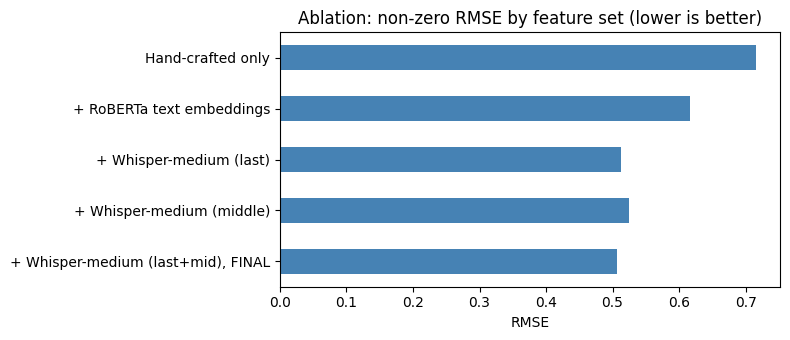

In [22]:
# Ablation: which feature groups matter? (Ridge, non-zero clips, same 5 folds)
variants = {
    "Hand-crafted only":          X_hand_tr,
    "+ RoBERTa text embeddings":  pd.concat([X_hand_tr, X_rob_tr], axis=1),
    "+ Whisper-medium (last)":    pd.concat([X_hand_tr, X_rob_tr, X_ml_tr], axis=1),
    "+ Whisper-medium (middle)":  pd.concat([X_hand_tr, X_rob_tr, X_mm_tr], axis=1),
    "+ Whisper-medium (last+mid), FINAL": X_v3_tr,
}
abl = {}
for name, X in variants.items():
    o = run_cv_nz(mk_ridge_w, X)
    abl[name] = rmse(y[nz], o[nz])
    print(f"{name:38s} non-zero RMSE {abl[name]:.4f}")

pd.Series(abl)[::-1].plot(kind="barh", figsize=(8, 3.5), color="steelblue",
                          title="Ablation: non-zero RMSE by feature set (lower is better)")
plt.xlabel("RMSE"); plt.tight_layout(); plt.show()

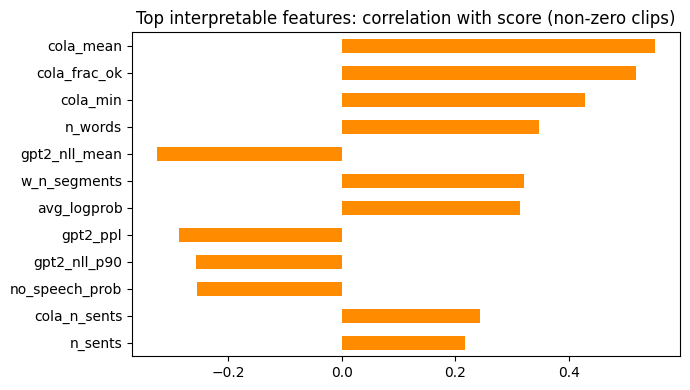

In [23]:
# Correlation of key interpretable features with the grade (real speech only)
chk = train_df[["key", "label"]].merge(feat_df.reset_index(), on="key")
chk = chk[chk["label"] > 0]
top = chk.drop(columns="key").corr()["label"].drop("label")
top = top.reindex(top.abs().sort_values(ascending=False).index)[:12]
top[::-1].plot(kind="barh", figsize=(7, 4), color="darkorange",
               title="Top interpretable features: correlation with score (non-zero clips)")
plt.tight_layout(); plt.show()

**Takeaway:** Sentence-level grammatical acceptability (CoLA) is the strongest interpretable signal. Fluency measured by GPT-2 loss is the second-strongest, and it is negative as expected. These are single-feature correlations on real-speech clips, not model importances. The final Ridge model also uses the audio embeddings, which carry the largest gain (see the ablation chart).

In [24]:
# Cell 22: Final pipeline, nested cross-validation
# prediction = (1 - p(zero)) * Ridge, then isotonic calibration. This is the honest estimate of test error.
X_v3_np, X_v3_te_np = X_v3_tr.values, X_v3_te.values

oof_v3 = np.zeros(len(y))
for tr, va in folds:
    p = mk_clf().fit(Ztr[tr], yz[tr]).predict_proba(Ztr[va])[:, 1]
    tr_nz = tr[nz[tr]]
    r = mk_ridge_w().fit(X_v3_np[tr_nz], y[tr_nz]).predict(X_v3_np[va])
    oof_v3[va] = np.clip((1 - p) * r, 0, 5)

oof_v3_cal = calibrated_oof(oof_v3)
report("Two-stage (uncalibrated)", oof_v3)
report("Two-stage + isotonic (FINAL)", oof_v3_cal)
print(f"RMSE non-zero rows: {rmse(y[nz], oof_v3_cal[nz]):.4f} | zero rows: {rmse(y[~nz], oof_v3_cal[~nz]):.4f}")

Two-stage (uncalibrated)           RMSE 0.5294 | MAE 0.3856 | Pearson 0.904 | Spearman 0.870
Two-stage + isotonic (FINAL)       RMSE 0.5238 | MAE 0.3751 | Pearson 0.906 | Spearman 0.863
RMSE non-zero rows: 0.5289 | zero rows: 0.4110


In [25]:
# Cell 23: Final fit, REQUIRED training RMSE, and submission file
# Fits on all training data. The training RMSE is optimistic; the CV RMSE above is the generalisation estimate.
clf_v3   = mk_clf().fit(Ztr, yz)
ridge_v3 = mk_ridge_w().fit(X_v3_np[nz], y[nz])
iso_v3   = IsotonicRegression(out_of_bounds="clip").fit(oof_v3, y)   # fitted on out-of-fold predictions
print("Final Ridge alpha:", ridge_v3[-1].alpha_)

def two_stage(Z, X):
    p = clf_v3.predict_proba(Z)[:, 1]
    return np.clip((1 - p) * ridge_v3.predict(X), 0, 5), p

tr_raw, _ = two_stage(Ztr, X_v3_np)
train_pred = np.clip(iso_v3.predict(tr_raw), 0, 5)
print("=" * 55)
print(f"TRAINING RMSE (final pipeline): {rmse(y, train_pred):.4f}")
print(f"CV RMSE (honest, nested):       {rmse(y, oof_v3_cal):.4f}")
print(f"Baseline RMSE (mean):           {rmse(y, base):.4f}")
print("=" * 55)

te_raw, te_p = two_stage(Zte, X_v3_te_np)
test_pred = np.clip(iso_v3.predict(te_raw), 0, 5)
submission = pd.DataFrame({"filename": test_df["filename"].values, "label": test_pred.round(4)})
assert len(submission) == 216 and submission["filename"].is_unique and submission["label"].notna().all()
submission.to_csv(f"{WORK_DIR}/submission_v3.csv", index=False)
submission.to_csv("/content/submission_v3.csv", index=False)
print(submission["label"].describe().round(3))

Final Ridge alpha: 1000
TRAINING RMSE (final pipeline): 0.2651
CV RMSE (honest, nested):       0.5238
Baseline RMSE (mean):           1.2383
count    216.000
mean       3.261
std        0.860
min        2.154
25%        2.615
50%        3.133
75%        3.692
max        4.951
Name: label, dtype: float64


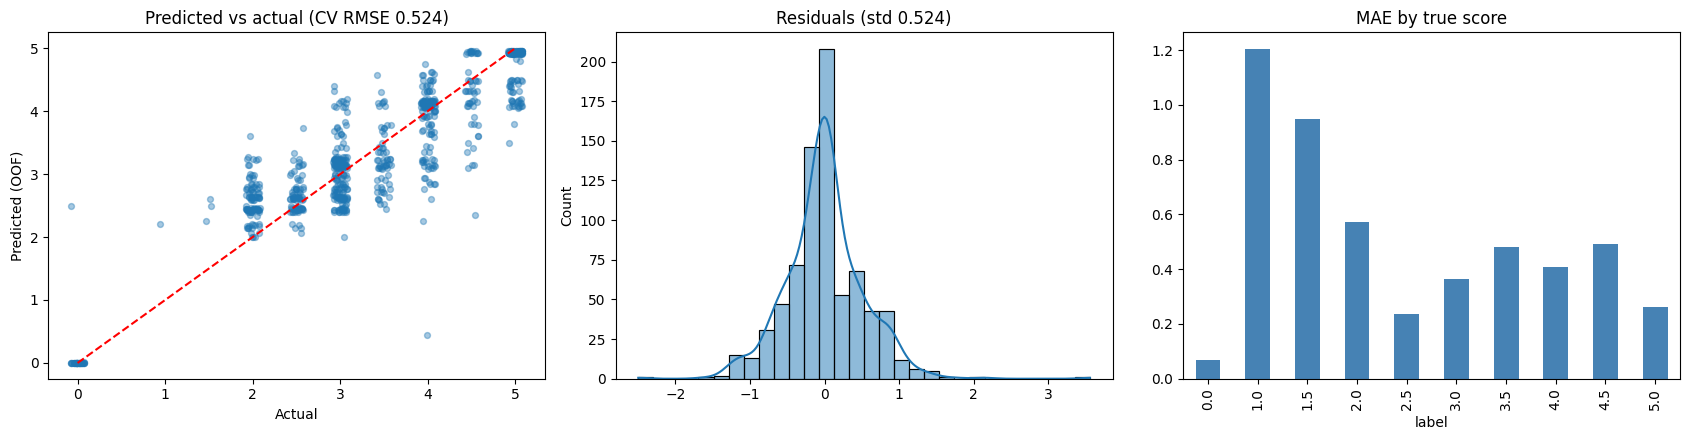

In [26]:
# Cell 24: Evaluation plots
# Predicted vs actual, residual distribution, and mean absolute error by true score (all out-of-fold).
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
res = y - oof_v3_cal
jit = np.random.RandomState(0).uniform(-0.08, 0.08, len(y))
ax[0].scatter(y + jit, oof_v3_cal, alpha=0.4, s=18); ax[0].plot([0, 5], [0, 5], "r--")
ax[0].set(xlabel="Actual", ylabel="Predicted (OOF)", title=f"Predicted vs actual (CV RMSE {rmse(y, oof_v3_cal):.3f})")
sns.histplot(res, bins=30, kde=True, ax=ax[1]); ax[1].set(title=f"Residuals (std {res.std():.3f})")
pd.DataFrame({"label": y, "abs_err": np.abs(res)}).groupby("label")["abs_err"].mean().plot(kind="bar", ax=ax[2], color="steelblue")
ax[2].set(title="MAE by true score")
plt.tight_layout(); plt.savefig(f"{WORK_DIR}/evaluation_plots_final.png", dpi=130); plt.show()

In [27]:
# Cell 25: Stability check
# Repeats CV with different fold seeds; differences smaller than ~0.02 between variants are within noise.
for seed in [1, 2, 3]:
    o = np.zeros(len(y))
    for tr, va in StratifiedKFold(n_splits=5, shuffle=True, random_state=seed).split(np.zeros(len(y)), strat):
        p = mk_clf().fit(Ztr[tr], yz[tr]).predict_proba(Ztr[va])[:, 1]
        tr_nz = tr[nz[tr]]
        r = mk_ridge_w().fit(X_v3_np[tr_nz], y[tr_nz]).predict(X_v3_np[va])
        o[va] = np.clip((1 - p) * r, 0, 5)
    print(f"fold seed {seed}: uncalibrated CV RMSE {rmse(y, o):.4f}")

fold seed 1: uncalibrated CV RMSE 0.5407
fold seed 2: uncalibrated CV RMSE 0.5299
fold seed 3: uncalibrated CV RMSE 0.5481


In [28]:
# Cell 26: Download the submission file
# submission_v3.csv: 216 rows, columns filename,label, in test.csv order.
from google.colab import files
files.download("/content/submission_v3.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>